# Evaluación 3 — Modelado Predictivo de Riesgo Crediticio
**Clasificación de solicitudes de crédito hipotecario con `DecisionTreeClassifier`**

| | |
|---|---|
| **Variable objetivo** | `Riesgo_Impago` (1 = Impago / Default, 0 = Cumple sus pagos) |
| **Semilla** | `random_state = 29` en todo el pipeline |
| **Costo de un Falso Negativo** (se aprueba a quien no paga) | **$1.500.000** |
| **Costo de un Falso Positivo** (se rechaza a quien sí paga) | **$200.000** |


### Estructura
1. Fase 1 — Diagnóstico y calidad de datos (EDA)
2. Fase 2 — Limpieza y tratamiento con `Pipeline` + `ColumnTransformer`
3. Fase 3 — División estratificada, modelo base y modelo optimizado (`GridSearchCV`, 5 hiperparámetros)
4. Fase 4 — Métricas (Recall y F2) e interpretación financiera de las matrices de confusión

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (recall_score, fbeta_score, precision_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, make_scorer,
                             classification_report)

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_STATE = 29          # semilla
TARGET = "Riesgo_Impago"
COSTO_FN = 1_500_000       # crédito otorgado que termina en impago
COSTO_FP = 200_000         # crédito viable denegado (pérdida de intereses)

# Paleta: azul = cumple (0), naranja = impago (1)
COLOR_CUMPLE, COLOR_IMPAGO = "#2a78d6", "#eb6834"
PALETA_TARGET = {0: COLOR_CUMPLE, 1: COLOR_IMPAGO}
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#898781", "grid.color": "#e6e5e1",
                                     "axes.titleweight": "bold", "figure.dpi": 110})

## Fase 1 — Diagnóstico y Calidad de Datos (EDA)
### 1.1 Carga del dataset `riesgo_crediticio.csv`
Se descarga desde el repositorio del grupo (carpeta `E3 - Clasiffier`). Si el archivo ya está en el directorio de trabajo, se usa directamente.

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/sebastianip3/EV-IA/main/E3%20-%20Clasiffier/riesgo_crediticio.csv"
DATA_FILE = "riesgo_crediticio.csv"

if not os.path.exists(DATA_FILE):
    exit_code = os.system(f"wget -q -O {DATA_FILE} '{DATA_URL}'")
    if exit_code != 0 or not os.path.exists(DATA_FILE) or os.path.getsize(DATA_FILE) == 0:
        raise FileNotFoundError(
            "No fue posible descargar el archivo con wget. "
            "Verifique la URL del repositorio o coloque el CSV en el directorio de trabajo."
        )

df_raw = pd.read_csv(DATA_FILE)
print(f"Registros cargados: {df_raw.shape[0]}  |  Variables: {df_raw.shape[1]}")
df_raw.head()

Registros cargados: 25000  |  Variables: 6


,Unnamed: 0,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso,Riesgo_Impago
0,0,"39,785.55","85,246.38",694.00,70.00,0
1,1,"69,773.95","244,260.00",622.00,10.65,0
2,2,"127,770.68","209,310.35",780.00,42.70,0
3,3,"16,799.80","213,059.98",741.00,48.04,0
4,4,"70,229.83","219,523.13",714.00,25.58,0


### 1.2 Estructura y tipos de datos

In [ ]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              25000 non-null  int64  
 1   Ingreso_Anual           25000 non-null  float64
 2   Monto_Prestamo          25000 non-null  float64
 3   Puntaje_Credito         25000 non-null  float64
 4   Relacion_Deuda_Ingreso  25000 non-null  float64
 5   Riesgo_Impago           25000 non-null  int64  
dtypes: float64(4), int64(2)
memory usage: 1.1 MB


In [ ]:
print("Columnas:", list(df_raw.columns))
col_idx = df_raw.columns[0]
es_indice = (df_raw[col_idx] == np.arange(len(df_raw))).all()
print(f"\nLa primera columna '{col_idx}' es un índice correlativo 0..n-1: {es_indice}")

Columnas: ['Unnamed: 0', 'Ingreso_Anual', 'Monto_Prestamo', 'Puntaje_Credito', 'Relacion_Deuda_Ingreso', 'Riesgo_Impago']

La primera columna 'Unnamed: 0' es un índice correlativo 0..n-1: True


**Hallazgo:** el archivo trae una columna sin nombre (`Unnamed: 0`) que es un **índice exportado** desde pandas (0, 1, 2, …). No aporta información del cliente y, si se dejara, el árbol podría usarla para "memorizar" el orden de las filas. **Se elimina**. Las cuatro variables predictoras son `float64` (continuas) y el target es `int64` binario, lo que coincide con el diccionario de datos.

In [ ]:
df = df_raw.drop(columns=[col_idx]).copy()
FEATURES = ["Ingreso_Anual", "Monto_Prestamo", "Puntaje_Credito", "Relacion_Deuda_Ingreso"]
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Ingreso_Anual,"25,000.00","55,824.44","29,804.90","7,832.12","35,051.32","49,234.68","68,923.52","348,135.55"
Monto_Prestamo,"25,000.00","220,162.89","60,059.30","50,000.00","179,438.08","220,241.47","261,003.36","451,784.21"
Puntaje_Credito,"25,000.00",680.03,59.78,457.00,640.00,680.00,721.00,850.00
Relacion_Deuda_Ingreso,"25,000.00",24.03,13.62,5.00,13.79,21.45,31.38,70.00
Riesgo_Impago,"25,000.00",0.07,0.26,0.00,0.00,0.00,0.00,1.00


### 1.3 Valores nulos y duplicados

In [ ]:
calidad = pd.DataFrame({
    "nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(2),
    "valores únicos": df.nunique(),
    "tipo": df.dtypes.astype(str),
})
display(calidad)
print(f"Filas duplicadas (todas las columnas): {df.duplicated().sum()}")
print(f"Filas con mismas features y distinto target: {df[df.duplicated(FEATURES, keep=False)].groupby(FEATURES)[TARGET].nunique().gt(1).sum()}")

,nulos,% nulos,valores únicos,tipo
Ingreso_Anual,0,0.00,24970,float64
Monto_Prestamo,0,0.00,24927,float64
Puntaje_Credito,0,0.00,373,float64
Relacion_Deuda_Ingreso,0,0.00,5109,float64
Riesgo_Impago,0,0.00,2,int64


Filas duplicadas (todas las columnas): 0
Filas con mismas features y distinto target: 0


**Hallazgo:** no hay valores nulos ni registros duplicados. Aun así, el pipeline de la Fase 2 incluye **imputación por mediana**: en producción llegarán solicitudes con campos vacíos y el modelo debe procesarlas sin fallar.

### 1.4 Inconsistencias lógicas (reglas de negocio)
Se contrasta cada variable con su dominio válido según el diccionario de datos:

| Variable | Regla de validez |
|---|---|
| `Ingreso_Anual` | > 0 |
| `Monto_Prestamo` | > 0 |
| `Puntaje_Credito` | entre 300 y 850 |
| `Relacion_Deuda_Ingreso` | entre 0 y 100 (%) |
| `Riesgo_Impago` | solo 0 o 1 |

In [ ]:
REGLAS = {
    "Ingreso_Anual":          (0, None, "≤ 0"),
    "Monto_Prestamo":         (0, None, "≤ 0"),
    "Puntaje_Credito":        (300, 850, "fuera de [300, 850]"),
    "Relacion_Deuda_Ingreso": (0, 100, "fuera de [0, 100]"),
}

filas = []
for col, (lo, hi, desc) in REGLAS.items():
    s = df[col]
    if hi is None:
        invalidos = (s <= lo).sum()
    else:
        invalidos = ((s < lo) | (s > hi)).sum()
    filas.append({"variable": col, "regla violada": desc, "registros inválidos": invalidos,
                  "mín": s.min(), "máx": s.max()})
filas.append({"variable": TARGET, "regla violada": "distinto de 0/1",
              "registros inválidos": (~df[TARGET].isin([0, 1])).sum(),
              "mín": df[TARGET].min(), "máx": df[TARGET].max()})
display(pd.DataFrame(filas))

# Puntaje de crédito debería ser entero
print(f"Puntajes de crédito con decimales: {(df['Puntaje_Credito'] % 1 != 0).sum()}")

,variable,regla violada,registros inválidos,mín,máx
0,Ingreso_Anual,≤ 0,0,"7,832.12","348,135.55"
1,Monto_Prestamo,≤ 0,0,"50,000.00","451,784.21"
2,Puntaje_Credito,"fuera de [300, 850]",0,457.00,850.00
3,Relacion_Deuda_Ingreso,"fuera de [0, 100]",0,5.00,70.00
4,Riesgo_Impago,distinto de 0/1,0,0.00,1.00


Puntajes de crédito con decimales: 0


Además de los rangos, se revisan **valores acumulados en los bordes** (señal de que los datos fueron *recortados* en origen) y la coherencia entre monto pedido e ingreso.

In [ ]:
bordes = pd.DataFrame({
    "condición": ["Puntaje_Credito = 850 (máximo de la escala)",
                  "Relacion_Deuda_Ingreso = 70 (máximo observado)",
                  "Relacion_Deuda_Ingreso = 5 (mínimo observado)",
                  "Monto_Prestamo = 50.000 (mínimo observado)"],
    "registros": [(df["Puntaje_Credito"] == 850).sum(),
                  (df["Relacion_Deuda_Ingreso"] == 70).sum(),
                  (df["Relacion_Deuda_Ingreso"] == 5).sum(),
                  (df["Monto_Prestamo"] == 50_000).sum()],
})
bordes["tasa de impago en el grupo"] = [
    df.loc[df["Puntaje_Credito"] == 850, TARGET].mean(),
    df.loc[df["Relacion_Deuda_Ingreso"] == 70, TARGET].mean(),
    df.loc[df["Relacion_Deuda_Ingreso"] == 5, TARGET].mean(),
    df.loc[df["Monto_Prestamo"] == 50_000, TARGET].mean(),
]
display(bordes.style.format({"tasa de impago en el grupo": "{:.1%}"}))

lti = df["Monto_Prestamo"] / df["Ingreso_Anual"]
print("Relación préstamo / ingreso anual (veces el ingreso):")
print(lti.describe().round(2).to_string())
print(f"\nSolicitudes que piden más de 10 veces su ingreso anual: {(lti > 10).sum()} ({(lti > 10).mean():.1%})")
print(f"Solicitudes que piden más de 20 veces su ingreso anual: {(lti > 20).sum()}")

,condición,registros,tasa de impago en el grupo
0,Puntaje_Credito = 850 (máximo de la escala),49,2.0%
1,Relacion_Deuda_Ingreso = 70 (máximo observado),196,50.5%
2,Relacion_Deuda_Ingreso = 5 (mínimo observado),631,0.8%
3,Monto_Prestamo = 50.000 (mínimo observado),53,1.9%


Relación préstamo / ingreso anual (veces el ingreso):
count   25,000.00
mean         5.07
std          3.15
min          0.34
25%          2.94
50%          4.34
75%          6.37
max         42.65

Solicitudes que piden más de 10 veces su ingreso anual: 1785 (7.1%)
Solicitudes que piden más de 20 veces su ingreso anual: 85


**Hallazgos de consistencia:**
- **No hay valores imposibles**: ningún ingreso o monto ≤ 0, ningún puntaje fuera de 300–850, ninguna DTI negativa o sobre 100 %, y el target es estrictamente binario. Los puntajes son todos enteros.
- **Datos truncados en los bordes**: 631 clientes tienen exactamente DTI = 5 % (piso), 196 exactamente DTI = 70 % (techo), 53 piden exactamente $50.000 y 49 tienen 850 puntos. Son topes del sistema de origen (valores "censurados"): el cliente con DTI = 70 % probablemente tiene una deuda real igual o mayor. Es relevante porque **la mitad (≈50 %) de los clientes con DTI = 70 % cae en impago**, frente a ≈7 % del total y < 1 % de los que tienen DTI = 5 %. Se mantienen: son reales y muy informativos.
- **Montos poco realistas respecto del ingreso**: 85 solicitudes piden más de 20 veces el ingreso anual (máximo ≈43 veces). No es imposible para una hipoteca, pero es atípico; el árbol puede aprenderlo, así que se conserva y se documenta.
- Por eso el pipeline incorpora igualmente una **regla de validación** que convierte en `NaN` cualquier valor fuera de dominio que llegue en el futuro, para que luego sea imputado.

### 1.5 Distribución y outliers

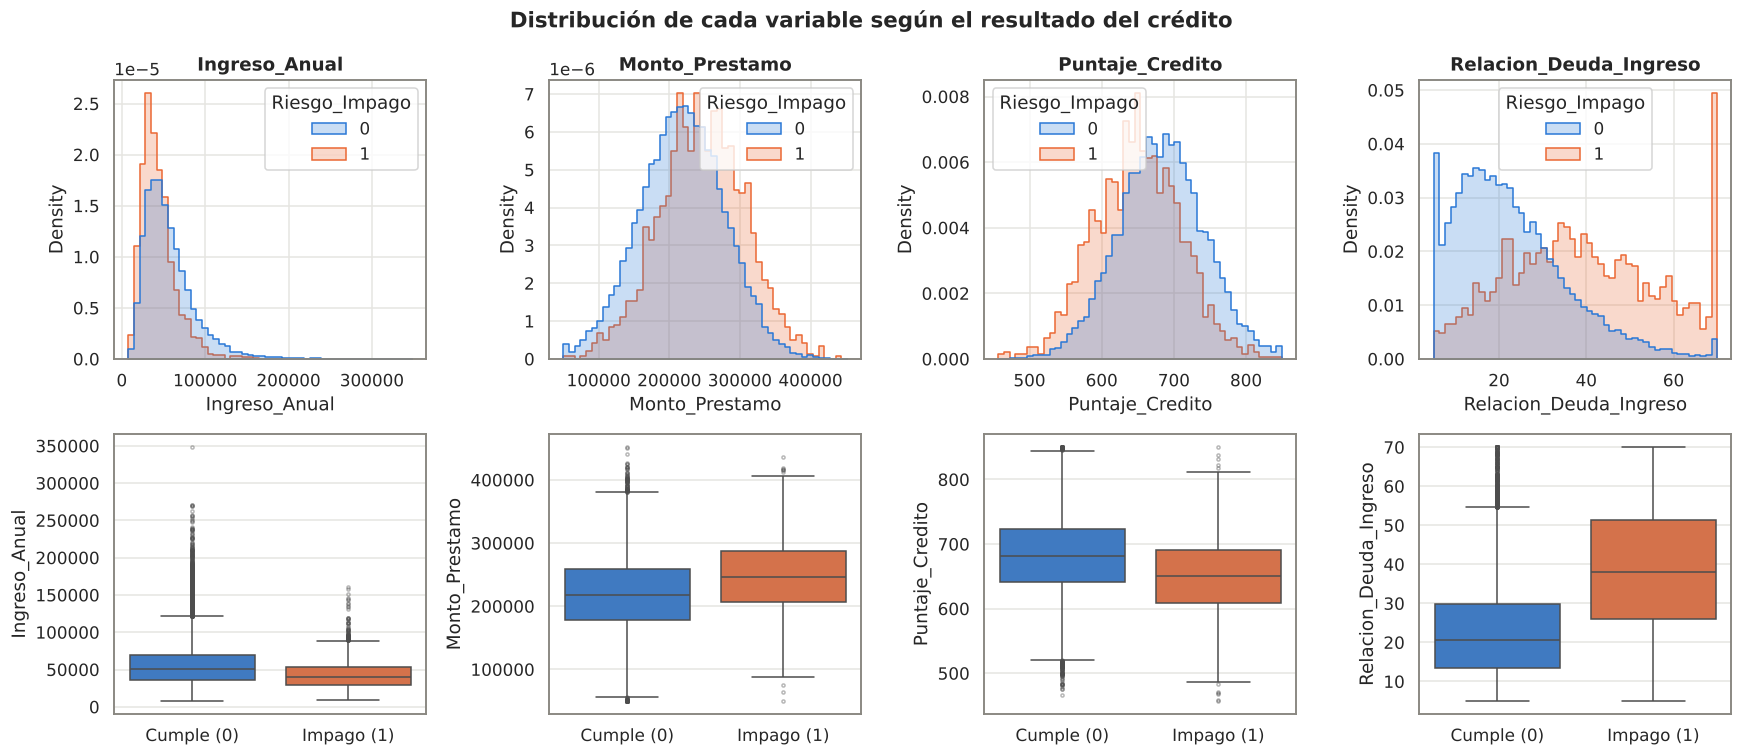

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, col in enumerate(FEATURES):
    sns.histplot(data=df, x=col, hue=TARGET, palette=PALETA_TARGET, bins=50,
                 stat="density", common_norm=False, element="step", ax=axes[0, i])
    axes[0, i].set_title(col)
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette=PALETA_TARGET, legend=False, ax=axes[1, i],
                flierprops={"markersize": 2, "alpha": .4})
    axes[1, i].set_xticks([0, 1]); axes[1, i].set_xticklabels(["Cumple (0)", "Impago (1)"])
    axes[1, i].set_xlabel("")
fig.suptitle("Distribución de cada variable según el resultado del crédito", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

In [ ]:
def outliers_iqr(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = pd.DataFrame({
    "outliers (IQR)": [outliers_iqr(df[c]) for c in FEATURES],
    "asimetría": [df[c].skew() for c in FEATURES],
}, index=FEATURES)
out["% outliers"] = (out["outliers (IQR)"] / len(df) * 100).round(2)
display(out)

,outliers (IQR),asimetría,% outliers
Ingreso_Anual,976,1.70,3.90
Monto_Prestamo,157,-0.00,0.63
Puntaje_Credito,167,-0.03,0.67
Relacion_Deuda_Ingreso,663,0.99,2.65


**Hallazgos de distribución:**
- `Ingreso_Anual` tiene **asimetría positiva fuerte** (≈1,7) y es la variable con más outliers (≈3,9 %): pocos clientes con ingresos muy altos (hasta $348 mil). Es el patrón típico de los ingresos, no un error.
- `Relacion_Deuda_Ingreso` también es asimétrica a la derecha (≈1,0): concentra 2,7 % de outliers, justamente los clientes más endeudados.
- `Monto_Prestamo` y `Puntaje_Credito` son casi simétricos y con pocos atípicos (< 1 %).
- **Decisión:** los outliers **no se eliminan** (son clientes reales y suelen ser los de mayor riesgo). En el pipeline se **acotan (winsorizan) a los percentiles 1 y 99 calculados solo con el set de entrenamiento**, para que valores extremos futuros no generen ramas espurias.
- Visualmente, los clientes en impago tienen **menor ingreso, menor puntaje de crédito, mayor DTI y piden montos algo mayores** (mediana ≈ $247 mil vs. ≈ $219 mil). La DTI es la variable que más separa ambos grupos.

### 1.6 Desbalance de la variable objetivo

,clientes,proporción
Riesgo_Impago,,
0 · Cumple,23211,92.84%
1 · Impago,1789,7.16%


Razón de desbalance: 13.0 clientes cumplidores por cada cliente en impago


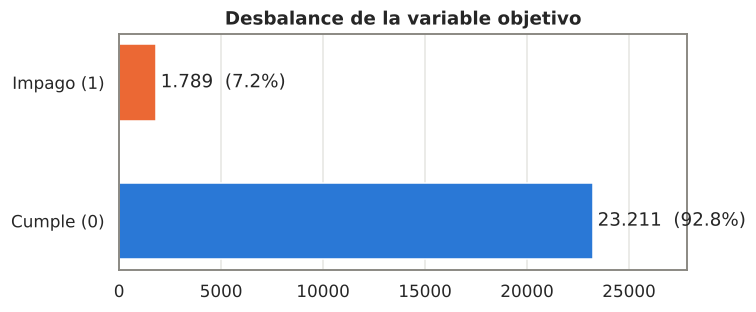

Un modelo que aprueba a TODOS tendría accuracy = 92.8% y no detectaría ni un impago.


In [ ]:
conteo = df[TARGET].value_counts().sort_index()
prop = df[TARGET].value_counts(normalize=True).sort_index()
display(pd.DataFrame({"clientes": conteo, "proporción": prop.map("{:.2%}".format)},
                     index=pd.Index([0, 1], name=TARGET)).rename(index={0: "0 · Cumple", 1: "1 · Impago"}))
print(f"Razón de desbalance: {conteo[0] / conteo[1]:.1f} clientes cumplidores por cada cliente en impago")

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(["Cumple (0)", "Impago (1)"], conteo.values, color=[COLOR_CUMPLE, COLOR_IMPAGO], height=.55)
for b, n, p in zip(bars, conteo.values, prop.values):
    ax.text(b.get_width() + 250, b.get_y() + b.get_height() / 2, f"{n:,}  ({p:.1%})".replace(",", "."), va="center")
ax.set_xlim(0, conteo.max() * 1.2); ax.set_title("Desbalance de la variable objetivo")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

# ¿Qué logra un modelo que no aprende nada?
dummy_acc = prop.max()
print(f"Un modelo que aprueba a TODOS tendría accuracy = {dummy_acc:.1%} y no detectaría ni un impago.")

**Hallazgo clave:** solo el **7,16 %** de los clientes cae en impago (1.789 de 25.000; razón ≈ 13:1). Consecuencias para el modelado:
1. **La accuracy es engañosa**: aprobar a todos da 92,8 % de "acierto" con cero valor de negocio.
2. La división train/test debe ser **estratificada** para conservar el 7,16 % en ambos conjuntos.
3. Un árbol sin ajustes tenderá a favorecer la clase mayoritaria; en la optimización se prueba `class_weight` para darle más peso al impago, coherente con que un FN cuesta **7,5 veces** más que un FP ($1.500.000 / $200.000).

### 1.7 Relación entre variables

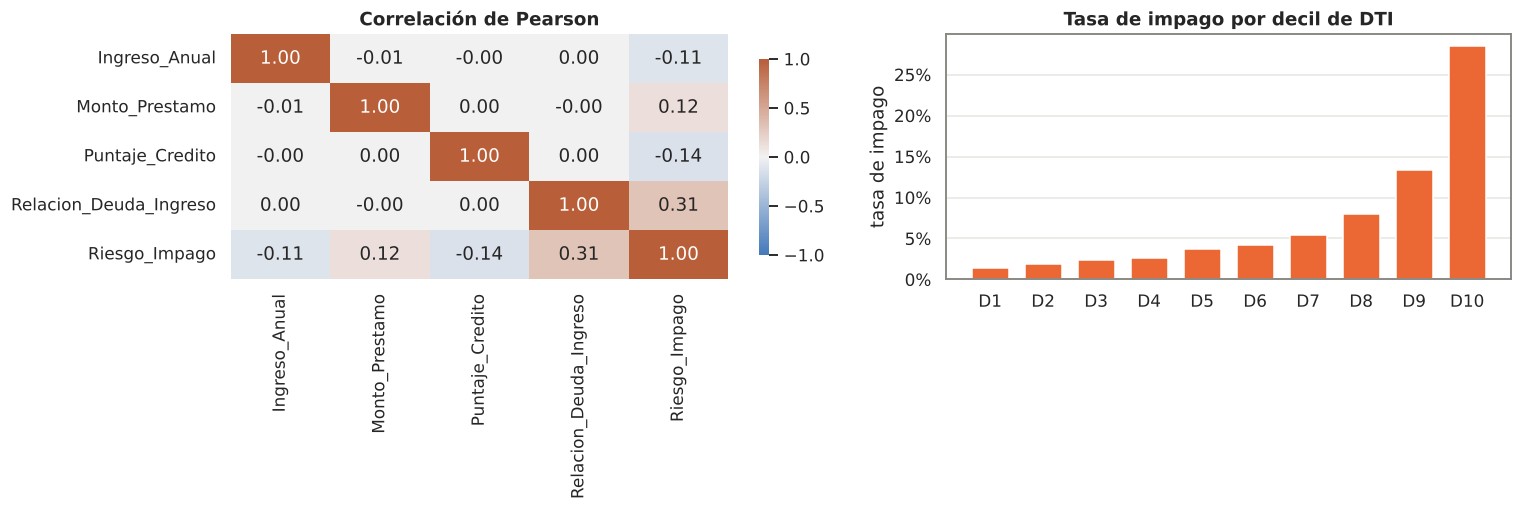

,correlación con el impago
Relacion_Deuda_Ingreso,0.31
Puntaje_Credito,-0.14
Monto_Prestamo,0.12
Ingreso_Anual,-0.11


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
corr = df.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.diverging_palette(250, 25, as_cmap=True),
            vmin=-1, vmax=1, center=0, ax=axes[0], cbar_kws={"shrink": .8})
axes[0].set_title("Correlación de Pearson")

tasa = (df.assign(tramo=pd.qcut(df["Relacion_Deuda_Ingreso"], 10))
          .groupby("tramo", observed=True)[TARGET].mean())
axes[1].bar(range(10), tasa.values, color=COLOR_IMPAGO, width=.7)
axes[1].set_xticks(range(10)); axes[1].set_xticklabels([f"D{i}" for i in range(1, 11)])
axes[1].set_title("Tasa de impago por decil de DTI"); axes[1].set_ylabel("tasa de impago")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).to_frame("correlación con el impago"))

**Lectura:** la **relación deuda/ingreso** es la variable más asociada al impago (correlación positiva) y la tasa de impago crece fuertemente en los últimos deciles de DTI. El **puntaje de crédito** y el **ingreso** se asocian negativamente (a más puntaje o ingreso, menos impago). No hay correlaciones altas entre predictores, por lo que no existe multicolinealidad problemática.

### Resumen de calidad (Fase 1)
| Aspecto | Resultado | Acción |
|---|---|---|
| Columna índice `Unnamed: 0` | Sobra (índice exportado) | Eliminar |
| Nulos | 0 | Imputador por mediana en el pipeline (robustez en producción) |
| Duplicados | 0 | — |
| Valores imposibles (≤ 0 / fuera de escala) | 0 | Regla de validación → `NaN` → imputación |
| Topes en bordes (DTI = 5 y 70, Score = 850, Monto = 50 mil) | 929 registros | Se conservan (reales e informativos) |
| Outliers IQR | Ingreso 3,9 %, DTI 2,7 % | Winsorización p1–p99 aprendida en train |
| Desbalance del target | 7,16 % impago (13:1) | Estratificación + `class_weight` + métricas centradas en la clase 1 |

## Fase 2 — Limpieza y Tratamiento de Datos (Pipeline)
Todo el tratamiento se encapsula en un **`Pipeline` de Scikit-Learn** con `ColumnTransformer`. Así cada estadístico (medianas, percentiles, medias y desviaciones) se aprende **solo con el set de entrenamiento** (y, dentro de la validación cruzada, solo con los *folds* de entrenamiento), evitando *data leakage*.

| Paso | Transformador | Qué hace | ¿Aprende de los datos? |
|---|---|---|---|
| 1 | `ValidadorDominio` | Valores fuera de dominio (ingreso ≤ 0, score fuera de 300–850, DTI fuera de 0–100) → `NaN` | No (reglas de negocio) |
| 2 | `CreadorVariables` | Crea `Prestamo_Ingreso` = monto / ingreso (veces el ingreso anual) | No |
| 3 | `SimpleImputer(median)` | Rellena nulos con la mediana | Sí → solo train |
| 4 | `Winsorizador(1, 99)` | Acota extremos a los percentiles 1 y 99 | Sí → solo train |
| 5 | `StandardScaler` | Estandariza (no cambia el árbol, deja el pipeline listo para otros modelos) | Sí → solo train |
| 6 | `DecisionTreeClassifier` | Modelo | Sí → solo train |

In [13]:
class ValidadorDominio(BaseEstimator, TransformerMixin):
    # Reemplaza por NaN los valores que violan las reglas de negocio.
    def __init__(self, reglas=None):
        self.reglas = reglas
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for col, (lo, hi) in (self.reglas or {}).items():
            if col in X:
                mask = X[col] <= lo if hi is None else (X[col] < lo) | (X[col] > hi)
                X.loc[mask, col] = np.nan
        return X


class CreadorVariables(BaseEstimator, TransformerMixin):
    # Agrega la razón préstamo / ingreso anual.
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = pd.DataFrame(X).copy()
        X["Prestamo_Ingreso"] = X["Monto_Prestamo"] / X["Ingreso_Anual"]
        return X


class Winsorizador(BaseEstimator, TransformerMixin):
    # Acota cada columna a los percentiles [inferior, superior] aprendidos en fit.
    def __init__(self, inferior=1, superior=99):
        self.inferior = inferior
        self.superior = superior
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lim_inf_ = np.nanpercentile(X, self.inferior, axis=0)
        self.lim_sup_ = np.nanpercentile(X, self.superior, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lim_inf_, self.lim_sup_)


REGLAS_DOMINIO = {
    "Ingreso_Anual": (0, None),
    "Monto_Prestamo": (0, None),
    "Puntaje_Credito": (300, 850),
    "Relacion_Deuda_Ingreso": (0, 100),
}
FEATURES_MODELO = FEATURES + ["Prestamo_Ingreso"]

tratamiento_numerico = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("winsorizar", Winsorizador(inferior=1, superior=99)),
    ("escalar", StandardScaler()),
])

def crear_preprocesador():
    return Pipeline([
        ("validar", ValidadorDominio(reglas=REGLAS_DOMINIO)),
        ("crear_variables", CreadorVariables()),
        ("columnas", ColumnTransformer([("num", tratamiento_numerico, FEATURES_MODELO)],
                                       remainder="drop", verbose_feature_names_out=False)),
    ])

def crear_pipeline(modelo):
    return Pipeline([("preprocesamiento", crear_preprocesador()), ("modelo", modelo)])

crear_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('validar', ...), ('crear_variables', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,reglas,"{'Ingreso_Anual': (0, ...), 'Monto_Prestamo': (0, ...), 'Puntaje_Credito': (300, ...), 'Relacion_Deuda_Ingreso': (0, ...)}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer o

**Prueba del pipeline:** se verifica que la regla de dominio y la imputación funcionan con un registro "sucio" simulado (no se usa para entrenar).

In [14]:
prueba = pd.DataFrame({
    "Ingreso_Anual": [-5000, np.nan], "Monto_Prestamo": [200000, 150000],
    "Puntaje_Credito": [950, 700], "Relacion_Deuda_Ingreso": [25, 130],
})
prep_demo = crear_preprocesador().fit(df[FEATURES])
salida = prep_demo.named_steps["validar"].transform(prueba)
print("Después de ValidadorDominio (valores inválidos → NaN):")
display(salida)
print("Después del preprocesamiento completo (sin nulos, escalado):")
display(pd.DataFrame(prep_demo.transform(prueba), columns=FEATURES_MODELO).round(3))

Después de ValidadorDominio (valores inválidos → NaN):


,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso
0,NaN,"200,000.00",NaN,25.00
1,NaN,"150,000.00",700.00,NaN


Después del preprocesamiento completo (sin nulos, escalado):


,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso,Prestamo_Ingreso
0,-0.22,-0.34,-0.00,0.07,-0.24
1,-0.22,-1.19,0.34,-0.19,-0.24


## Fase 3 — Construcción del Modelo
### 3.1 División entrenamiento / prueba (80 / 20, estratificada)

In [15]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

resumen_split = pd.DataFrame({
    "registros": [len(y), len(y_train), len(y_test)],
    "impagos": [y.sum(), y_train.sum(), y_test.sum()],
    "% impago": [y.mean(), y_train.mean(), y_test.mean()],
}, index=["Total", "Entrenamiento", "Prueba"])
display(resumen_split.style.format({"% impago": "{:.2%}", "registros": "{:,}", "impagos": "{:,}"}))

,registros,impagos,% impago
Total,"25,000","1,789",7.16%
Entrenamiento,"20,000","1,431",7.16%
Prueba,"5,000",358,7.16%


La estratificación mantiene la tasa de impago (≈7,16 %) idéntica en entrenamiento y prueba, de modo que la evaluación refleja la realidad del negocio. El set de prueba (5.000 clientes) **no se usa en ningún ajuste**: solo para la evaluación final.

### 3.2 Modelo base (línea base): `DecisionTreeClassifier` por defecto

In [16]:
modelo_base = crear_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))
modelo_base.fit(X_train, y_train)

arbol_base = modelo_base.named_steps["modelo"]
print(f"Profundidad del árbol base: {arbol_base.get_depth()}  |  Hojas: {arbol_base.get_n_leaves():,}")
print(f"Recall en ENTRENAMIENTO: {recall_score(y_train, modelo_base.predict(X_train)):.3f}")
print(f"Recall en PRUEBA:        {recall_score(y_test, modelo_base.predict(X_test)):.3f}")

Profundidad del árbol base: 30  |  Hojas: 1,593
Recall en ENTRENAMIENTO: 1.000
Recall en PRUEBA:        0.346


El árbol por defecto crece sin límite (profundidad y número de hojas muy altos) y **memoriza** el entrenamiento (recall 1,0) pero cae drásticamente en prueba: es un caso claro de **sobreajuste**. Esto motiva la optimización.

### 3.3 Modelo optimizado: `GridSearchCV` con 5 hiperparámetros
**Espacio de búsqueda (justificación):**

| Hiperparámetro | Valores | Por qué |
|---|---|---|
| `criterion` | gini, entropy | Dos formas de medir la impureza de cada corte |
| `max_depth` | 3, 4, 5, 6, 8, 10 | Controla la complejidad; el árbol base sobreajusta con profundidad ilimitada |
| `min_samples_split` | 2, 20, 50 | Exige un mínimo de clientes para seguir dividiendo un nodo |
| `min_samples_leaf` | 1, 10, 25, 50 | Evita hojas con muy pocos clientes (reglas poco confiables) |
| `class_weight` | None, balanced, {0: 1, 1: 7.5} | Corrige el desbalance. **{0:1, 1:7.5}** traduce la matriz de costos del negocio: un impago no detectado pesa 7,5 veces más ($1,5 M / $0,2 M) |

**Validación:** `StratifiedKFold` de 5 *folds* con `shuffle=True` y `random_state=29` (cada fold conserva el 7,16 % de impagos). Como el preprocesamiento está **dentro** del pipeline, se re-ajusta en cada fold → sin fuga de datos.

**Criterio de selección:** **F2-score** de la clase impago (ver justificación en la Fase 4). Total: 2 × 6 × 3 × 4 × 3 = **432 combinaciones × 5 folds = 2.160 entrenamientos**.

In [17]:
param_grid = {
    "modelo__criterion": ["gini", "entropy"],
    "modelo__max_depth": [3, 4, 5, 6, 8, 10],
    "modelo__min_samples_split": [2, 20, 50],
    "modelo__min_samples_leaf": [1, 10, 25, 50],
    "modelo__class_weight": [None, "balanced", {0: 1, 1: COSTO_FN / COSTO_FP}],
}

f2_scorer = make_scorer(fbeta_score, beta=2)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

busqueda = GridSearchCV(
    estimator=crear_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    param_grid=param_grid,
    scoring={"F2": f2_scorer, "Recall": "recall"},
    refit="F2",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
busqueda.fit(X_train, y_train)

modelo_opt = busqueda.best_estimator_
print("Mejores hiperparámetros:")
for k, v in busqueda.best_params_.items():
    print(f"  {k.replace('modelo__', ''):<18} = {v}")
print(f"\nF2 promedio en validación cruzada: {busqueda.best_score_:.3f}")

Mejores hiperparámetros:
  class_weight       = {0: 1, 1: 7.5}
  criterion          = entropy
  max_depth          = 6
  min_samples_leaf   = 25
  min_samples_split  = 2

F2 promedio en validación cruzada: 0.470


In [18]:
res = pd.DataFrame(busqueda.cv_results_)
cols = ["param_modelo__criterion", "param_modelo__max_depth", "param_modelo__min_samples_split",
        "param_modelo__min_samples_leaf", "param_modelo__class_weight",
        "mean_test_F2", "std_test_F2", "mean_test_Recall", "mean_train_F2"]
top = res.sort_values("rank_test_F2")[cols].head(8).copy()
top.columns = ["criterion", "max_depth", "min_split", "min_leaf", "class_weight",
               "F2 val", "F2 desv", "Recall val", "F2 train"]
top["class_weight"] = top["class_weight"].map(str)
display(top.round(3))

# Efecto de class_weight (mejor F2 alcanzado con cada opción)
efecto = res.assign(cw=res["param_modelo__class_weight"].map(str)).groupby("cw")["mean_test_F2"].max()
display(efecto.rename("mejor F2 en validación").to_frame().round(3))

,criterion,max_depth,min_split,min_leaf,class_weight,F2 val,F2 desv,Recall val,F2 train
404,entropy,6,50,25,"{0: 1, 1: 7.5}",0.47,0.04,0.59,0.52
402,entropy,6,2,25,"{0: 1, 1: 7.5}",0.47,0.04,0.59,0.52
403,entropy,6,20,25,"{0: 1, 1: 7.5}",0.47,0.04,0.59,0.52
405,entropy,6,2,50,"{0: 1, 1: 7.5}",0.47,0.03,0.59,0.52
407,entropy,6,50,50,"{0: 1, 1: 7.5}",0.47,0.03,0.59,0.52
406,entropy,6,20,50,"{0: 1, 1: 7.5}",0.47,0.03,0.59,0.52
398,entropy,6,50,1,"{0: 1, 1: 7.5}",0.47,0.03,0.59,0.52
346,gini,8,20,50,"{0: 1, 1: 7.5}",0.47,0.01,0.61,0.55


,mejor F2 en validación
cw,
None,0.25
balanced,0.46
"{0: 1, 1: 7.5}",0.47


**Lectura de la búsqueda:** las mejores combinaciones usan **`class_weight = {0:1, 1:7.5}`** (la matriz de costos del negocio) y profundidad moderada (6–8); los parámetros de tamaño mínimo (`min_samples_split`, `min_samples_leaf`) afinan el resultado en menor medida. La diferencia entre F2 de entrenamiento y de validación es pequeña: el modelo optimizado **generaliza**, a diferencia del base. Sin ponderación de clases (`None`) el F2 cae de forma importante (ver tabla): el desbalance es el principal obstáculo del problema.

Profundidad: 6  |  Hojas: 56  (vs. 30 y 1,593 del modelo base)


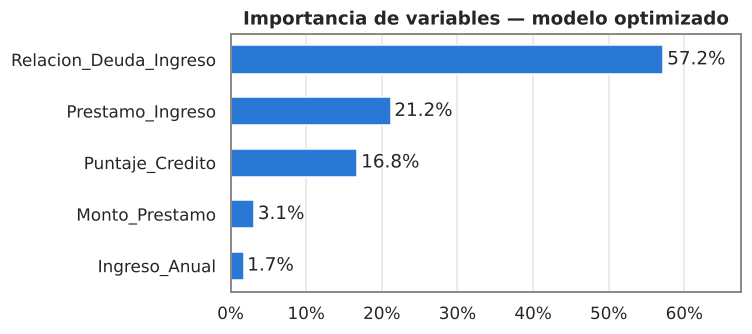

In [19]:
arbol_opt = modelo_opt.named_steps["modelo"]
print(f"Profundidad: {arbol_opt.get_depth()}  |  Hojas: {arbol_opt.get_n_leaves()}  "
      f"(vs. {arbol_base.get_depth()} y {arbol_base.get_n_leaves():,} del modelo base)")

imp = pd.Series(arbol_opt.feature_importances_, index=FEATURES_MODELO).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(imp.index, imp.values, color=COLOR_CUMPLE, height=.55)
for i, v in enumerate(imp.values):
    ax.text(v + .005, i, f"{v:.1%}", va="center")
ax.set_xlim(0, imp.max() * 1.18); ax.set_title("Importancia de variables — modelo optimizado")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## Fase 4 — Evaluación e Interpretación de Métricas
### 4.1 Selección y justificación de las DOS métricas

Con un 7,16 % de impagos y un costo de error **asimétrico** (FN = $1.500.000 vs. FP = $200.000), la **accuracy** no sirve: aprobar a todos da 92,8 % y no detecta a nadie. Se eligen dos métricas centradas en la clase **impago (1)**:

1. **Recall (sensibilidad) de la clase impago** = VP / (VP + FN).
   *¿Qué porcentaje de los clientes que no pagarán logramos detectar?* Cada impago no detectado (FN) es el error más caro del negocio, así que es la métrica que más directamente mide la protección del capital.

2. **F2-score de la clase impago** = (1 + 2²) · Precisión · Recall / (2² · Precisión + Recall).
   El recall por sí solo se puede "inflar" rechazando a todos (recall = 100 %, pero se pierde todo el negocio sano). El F2 combina recall y precisión, dándole al **recall 4 veces más importancia** que a la precisión (β = 2). Esto refleja que en este negocio es peor dejar pasar un impago que rechazar a un buen cliente, sin ignorar el costo de los rechazos. Es la métrica usada para elegir el modelo en `GridSearchCV`.

Como complemento (no como métrica de selección) se reportan precisión, accuracy y el **costo financiero total** calculado con los costos del enunciado.

In [20]:
def evaluar(nombre, modelo):
    pred = modelo.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {
        "Modelo": nombre,
        "Recall (impago)": recall_score(y_test, pred),
        "F2 (impago)": fbeta_score(y_test, pred, beta=2),
        "Precisión (impago)": precision_score(y_test, pred, zero_division=0),
        "Accuracy": accuracy_score(y_test, pred),
        "VN": tn, "FP": fp, "FN": fn, "VP": tp,
        "Costo FN": fn * COSTO_FN, "Costo FP": fp * COSTO_FP,
        "Costo total": fn * COSTO_FN + fp * COSTO_FP,
    }

aprobar_todos = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
resultados = pd.DataFrame([
    evaluar("Sin modelo (aprobar a todos)", aprobar_todos),
    evaluar("Línea base (árbol por defecto)", modelo_base),
    evaluar("Optimizado (GridSearchCV)", modelo_opt),
]).set_index("Modelo")

metricas = resultados[["Recall (impago)", "F2 (impago)", "Precisión (impago)", "Accuracy"]]
display(metricas.style.format("{:.1%}").set_caption("Métricas sobre el conjunto de PRUEBA (5.000 clientes)")
        .highlight_max(subset=["Recall (impago)", "F2 (impago)"], color="#cde2fb"))

,Recall (impago),F2 (impago),Precisión (impago),Accuracy
Modelo,,,,
Sin modelo (aprobar a todos),0.0%,0.0%,0.0%,92.8%
Línea base (árbol por defecto),34.6%,33.1%,28.2%,89.0%
Optimizado (GridSearchCV),62.3%,49.6%,27.3%,85.4%


In [21]:
fmt_m = lambda v: f"${v/1e6:,.1f} M".replace(",", "X").replace(".", ",").replace("X", ".")
costos = resultados[["VN", "FP", "FN", "VP", "Costo FN", "Costo FP", "Costo total"]].copy()
display(costos.style.format({c: fmt_m for c in ["Costo FN", "Costo FP", "Costo total"]})
        .set_caption("Costo financiero en el set de prueba"))

c_base = resultados.loc["Línea base (árbol por defecto)", "Costo total"]
c_opt = resultados.loc["Optimizado (GridSearchCV)", "Costo total"]
c_dummy = resultados.loc["Sin modelo (aprobar a todos)", "Costo total"]
print(f"Ahorro del optimizado vs. línea base:    {fmt_m(c_base - c_opt)}  ({(c_base - c_opt) / c_base:.1%})")
print(f"Ahorro del optimizado vs. aprobar todos: {fmt_m(c_dummy - c_opt)}  ({(c_dummy - c_opt) / c_dummy:.1%})")

,VN,FP,FN,VP,Costo FN,Costo FP,Costo total
Modelo,,,,,,,
Sin modelo (aprobar a todos),4642,0,358,0,"$537,0 M","$0,0 M","$537,0 M"
Línea base (árbol por defecto),4326,316,234,124,"$351,0 M","$63,2 M","$414,2 M"
Optimizado (GridSearchCV),4047,595,135,223,"$202,5 M","$119,0 M","$321,5 M"


Ahorro del optimizado vs. línea base:    $92,7 M  (22.4%)
Ahorro del optimizado vs. aprobar todos: $215,5 M  (40.1%)


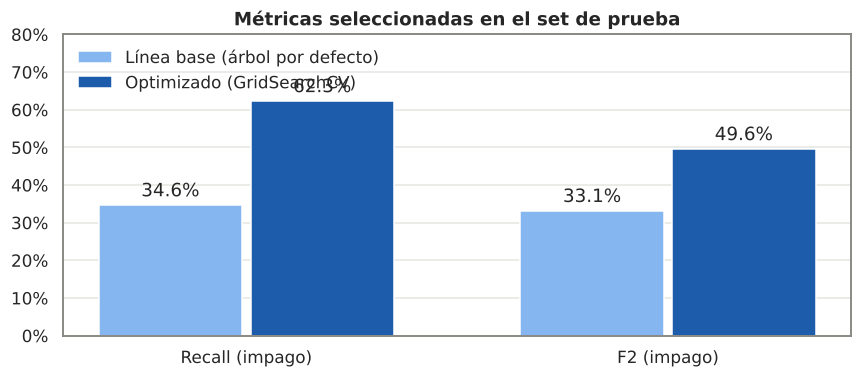

In [22]:
fig, ax = plt.subplots(figsize=(8, 3.6))
m = metricas[["Recall (impago)", "F2 (impago)"]].drop("Sin modelo (aprobar a todos)")
x = np.arange(len(m.columns)); w = .34
for i, (nombre, fila) in enumerate(m.iterrows()):
    color = "#86b6ef" if i == 0 else "#1c5cab"
    b = ax.bar(x + (i - .5) * (w + .02), fila.values, w, color=color, label=nombre)
    ax.bar_label(b, labels=[f"{v:.1%}" for v in fila.values], padding=3)
ax.set_xticks(x); ax.set_xticklabels(m.columns); ax.set_ylim(0, .8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Métricas seleccionadas en el set de prueba"); ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

### 4.2 Matrices de confusión
Convención: **clase positiva = impago (1)**. Filas = realidad, columnas = predicción del modelo.

| Celda | Significado en el banco | Costo |
|---|---|---|
| **VN** (0 → 0) | Buen cliente aprobado | Ganancia normal |
| **FP** (0 → 1) | Buen cliente **rechazado** | $200.000 de intereses perdidos |
| **FN** (1 → 0) | Cliente moroso **aprobado** | $1.500.000 de capital perdido |
| **VP** (1 → 1) | Cliente moroso rechazado a tiempo | Pérdida evitada |

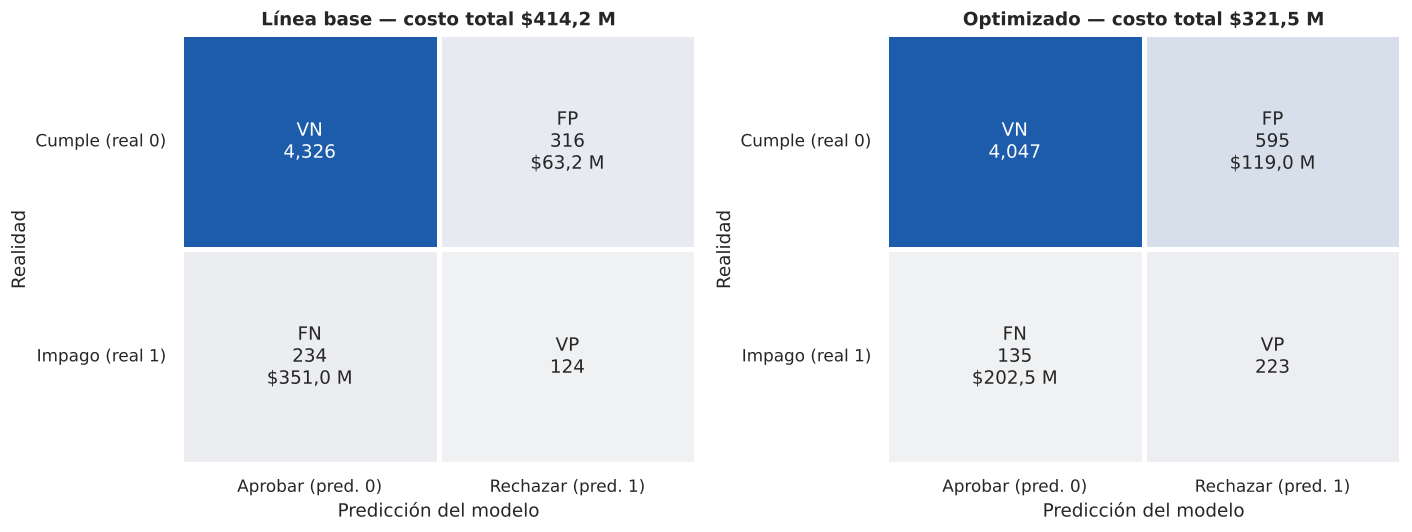

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (nombre, modelo) in zip(axes, [("Línea base", modelo_base), ("Optimizado", modelo_opt)]):
    cm = confusion_matrix(y_test, modelo.predict(X_test))
    etiquetas = np.array([[f"VN\n{cm[0,0]:,}", f"FP\n{cm[0,1]:,}\n{fmt_m(cm[0,1]*COSTO_FP)}"],
                          [f"FN\n{cm[1,0]:,}\n{fmt_m(cm[1,0]*COSTO_FN)}", f"VP\n{cm[1,1]:,}"]])
    sns.heatmap(cm, annot=etiquetas, fmt="", cmap=sns.light_palette("#1c5cab", as_cmap=True),
                cbar=False, ax=ax, linewidths=2, linecolor="white", annot_kws={"fontsize": 12})
    ax.set_xticklabels(["Aprobar (pred. 0)", "Rechazar (pred. 1)"])
    ax.set_yticklabels(["Cumple (real 0)", "Impago (real 1)"], rotation=0)
    ax.set_xlabel("Predicción del modelo"); ax.set_ylabel("Realidad")
    ax.set_title(f"{nombre} — costo total {fmt_m(cm[1,0]*COSTO_FN + cm[0,1]*COSTO_FP)}")
plt.tight_layout(); plt.show()

In [24]:
print("Reporte de clasificación — Línea base")
print(classification_report(y_test, modelo_base.predict(X_test), target_names=["Cumple", "Impago"], digits=3))
print("Reporte de clasificación — Optimizado")
print(classification_report(y_test, modelo_opt.predict(X_test), target_names=["Cumple", "Impago"], digits=3))

Reporte de clasificación — Línea base
              precision    recall  f1-score   support

      Cumple      0.949     0.932     0.940      4642
      Impago      0.282     0.346     0.311       358

    accuracy                          0.890      5000
   macro avg      0.615     0.639     0.626      5000
weighted avg      0.901     0.890     0.895      5000

Reporte de clasificación — Optimizado
              precision    recall  f1-score   support

      Cumple      0.968     0.872     0.917      4642
      Impago      0.273     0.623     0.379       358

    accuracy                          0.854      5000
   macro avg      0.620     0.747     0.648      5000
weighted avg      0.918     0.854     0.879      5000



In [25]:
# Valores para la interpretación
rb = resultados.loc["Línea base (árbol por defecto)"]; ro = resultados.loc["Optimizado (GridSearchCV)"]
total_impagos = int(y_test.sum()); total_cumple = int((y_test == 0).sum())
print(f"Set de prueba: {total_cumple:,} cumplidores y {total_impagos} impagos\n")
for nombre, r in [("LÍNEA BASE", rb), ("OPTIMIZADO", ro)]:
    print(f"{nombre}: detecta {int(r.VP)} de {total_impagos} impagos ({r.VP/total_impagos:.1%}), "
          f"deja pasar {int(r.FN)} ({fmt_m(r['Costo FN'])}), rechaza {int(r.FP)} buenos clientes "
          f"({r.FP/total_cumple:.1%} de los cumplidores, {fmt_m(r['Costo FP'])})")

Set de prueba: 4,642 cumplidores y 358 impagos

LÍNEA BASE: detecta 124 de 358 impagos (34.6%), deja pasar 234 ($351,0 M), rechaza 316 buenos clientes (6.8% de los cumplidores, $63,2 M)
OPTIMIZADO: detecta 223 de 358 impagos (62.3%), deja pasar 135 ($202,5 M), rechaza 595 buenos clientes (12.8% de los cumplidores, $119,0 M)


### 4.3 Interpretación — Modelo línea base
*(Valores del set de prueba: 5.000 clientes, de los cuales 358 son impagos.)*

- **VP = 124:** el árbol por defecto solo detecta **1 de cada 3 clientes morosos** (recall ≈ 35 %).
- **FN = 234:** **dos de cada tres morosos son aprobados**. Es la celda que más daño hace: 234 × $1.500.000 = **$351 millones** en capital no recuperado, **el 85 % del costo total** del modelo.
- **FP = 316:** se rechazan 316 buenos clientes (6,8 % de los cumplidores), con ≈ **$63,2 millones** en intereses perdidos. Además, la **precisión es de solo 28 %**: de cada 4 alertas de riesgo, casi 3 son falsas.
- **VN = 4.326:** la gran mayoría de buenos clientes son aprobados correctamente, pero esto es "fácil" dado el desbalance.
- **Diagnóstico:** el árbol creció sin restricciones, memorizó el entrenamiento y aprendió reglas basadas en pocos clientes que no generalizan. Además, al tratar ambos errores como iguales, no refleja que dejar pasar un impago cuesta 7,5 veces más que rechazar a un buen cliente. **Costo total ≈ $414,2 millones**, solo un 23 % mejor que no usar ningún modelo ($537 millones).

### 4.4 Interpretación — Modelo optimizado
- **VP = 223:** detecta **62 % de los morosos** (recall casi el doble que el base). Son 99 impagos adicionales frenados antes de desembolsar.
- **FN = 135:** los morosos aprobados bajan de 234 a 135 (**−42 %**). La pérdida de capital cae de $351 M a **$202,5 M**: **$148,5 millones menos** de pérdida directa.
- **FP = 595:** el costo de esta mejora es rechazar más buenos clientes (595 vs. 316; ≈ 12,8 % de los cumplidores), lo que equivale a **$119 millones** en intereses no ganados. La precisión se mantiene en ≈ 27 %: cada rechazo sigue requiriendo criterio, por lo que **se recomienda usar la alerta para derivar a revisión manual o pedir garantías/aval**, no para rechazar automáticamente.
- **Balance neto:** el aumento de FP cuesta ≈ $55,8 M más, pero la reducción de FN ahorra $148,5 M. **Costo total ≈ $321,5 M**: un **22 % menos que la línea base** (≈ $92,7 M de ahorro) y un **40 % menos que aprobar a todos**.
- **Por qué funciona:** `class_weight = {0:1, 1:7.5}` incorpora en el entrenamiento la misma asimetría de costos del negocio, y los límites de profundidad y tamaño de hoja producen un árbol más simple (profundidad 6) que generaliza.

### 4.5 Conclusiones
1. **Calidad de datos:** el dataset está limpio (sin nulos, duplicados ni valores imposibles); los principales desafíos son el **desbalance (7,16 % impago)**, la asimetría de ingreso y DTI y los valores truncados en los bordes. El pipeline queda preparado para datos sucios en producción sin fuga de información.
2. **Métricas:** Recall y F2 de la clase impago son las adecuadas porque miden lo que le importa al banco —no dejar pasar morosos— sin premiar el rechazo masivo. La accuracy sería engañosa.
3. **Resultado:** el modelo optimizado mejora el Recall de 35 % a 62 % y el F2 de 0,33 a 0,50, y **reduce el costo esperado en ≈ $92,7 millones por cada 5.000 solicitudes** respecto de la línea base.
4. **Recomendación de uso:** emplear el modelo como **filtro de alerta temprana**: aprobar automáticamente a los clientes clasificados como "cumple" y enviar los clasificados como "riesgo" a evaluación manual. Las variables decisivas son la relación deuda/ingreso, el puntaje de crédito y el ingreso.
5. **Próximos pasos:** probar modelos de ensamble (Random Forest, Gradient Boosting), ajustar el umbral de decisión según el costo y monitorear el desempeño con datos nuevos.